# Local search: expand to the next city, or stay home?
## The numbers behind the slides, run end to end

MSDS 692 practicum, Regis University. Michael Elliott.

This notebook runs the same code as `src/` on the real files and keeps the outputs, so the
numbers and charts can be read here without the data. The real files are not in the repo
(they belong to the businesses). If `data/private/` is missing, every cell falls back to the
fake sample data and the numbers mean nothing.

Saved outputs below come from the real files, run on 2026-10-18.

Sections: 1 rank-tracker share · 2 synthetic control (slide 6) · 3 reach (slide 7) ·
4 top 3 at home (slide 4) · 5 confusion matrix and stats · 6 summary against the slides

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import reach, synthetic_control as sc, top3_classifier as clf, sample_data

PRIVATE = ROOT / "data" / "private"
if (PRIVATE / "geogrids.parquet").exists() and (PRIVATE / "gsc_daily.parquet").exists():
    GEO, GSC = PRIVATE / "geogrids.parquet", PRIVATE / "gsc_daily.parquet"
    THREE = ["Specialty Barbershop", "Latin Dance Studio", "Integrative Health Clinic"]
    TREATED, DONORS = "Specialty Barbershop", ["Insulation Contractor", "Dental Practice", "Fractional-CTO Consultancy", "Latin Dance Studio"]
    print("running on the real files (not in the repo)")
else:
    if not (ROOT / "data" / "sample" / "geogrids.parquet").exists():
        sample_data.make()
    GEO, GSC = ROOT / "data" / "sample" / "geogrids.parquet", ROOT / "data" / "sample" / "gsc_daily.parquet"
    THREE = ["Sample barbershop", "Sample dance studio", "Sample clinic"]
    TREATED, DONORS = "Sample barbershop", ["Sample insulation contractor", "Sample dental practice", "Sample consultancy", "Sample dance studio"]
    print("running on the fake sample data: the numbers below mean nothing")

CHANGE, POST_END, PRE_START = pd.Timestamp("2026-09-20"), pd.Timestamp("2026-09-29"), pd.Timestamp("2026-07-16")
pd.set_option("display.width", 140)

running on the real files (not in the repo)


## 1. The rank tracker in Search Console

A desktop row with zero clicks, 20 or more impressions on that phrase that day, and average
position 2.5 or better is a rank tracker, not a person. This is removed before anything else.

In [2]:
g, daily = sc.load(GSC)
tot = g.groupby("client").impressions.sum()
ours = g[g.is_scan].groupby("client").impressions.sum().reindex(tot.index, fill_value=0)
share = pd.DataFrame({"impressions": tot, "from the tracker": ours, "share": (100 * ours / tot).round(1)})
share

,impressions,from the tracker,share
client,,,
Dental Practice,15478,0,0.0
Fractional-CTO Consultancy,1486,39,2.6
Insulation Contractor,9108,1021,11.2
Integrative Health Clinic,14824,10930,73.7
Latin Dance Studio,18679,1423,7.6
Specialty Barbershop,2596,1367,52.7


## 2. Did the September change move impressions? (slide 6)

Ridge regression of the treated business's daily log impressions on four untouched businesses
plus day of week, fitted on the days before the change. Then the ten days after are compared
with what the model expected. Then placebos: fake earlier dates, and each donor as if treated.

In [3]:
r = sc.fit_predict(daily, TREATED, DONORS, PRE_START, CHANGE, POST_END)
print(f"{TREATED}, change on {CHANGE.date()}")
print(f"  pre period: {r['pre_days']} days, ridge alpha {r['alpha']}, fit on the log scale R2 {r['pre_r2_log']}")
print(f"  {r['post_days']} days after: {r['post_actual']} impressions, model expected {r['post_model']}")
print(f"  difference {r['effect']:+.1f} ({r['effect_pct']:+.1f}%)")
pl = sc.placebos(daily, TREATED, DONORS, PRE_START, CHANGE, r["post_days"])
bigger = sum(abs(p["effect_pct"]) >= abs(r["effect_pct"]) for p in pl)
print(f"\nplacebos: {len(pl)}, {bigger} as big as the real difference or bigger")
pd.DataFrame(pl)

Specialty Barbershop, change on 2026-09-20
  pre period: 66 days, ridge alpha 3, fit on the log scale R2 0.351
  10 days after: 98 impressions, model expected 110.5
  difference -12.5 (-11.3%)

placebos: 8, 4 as big as the real difference or bigger


,kind,label,effect_pct
0,earlier date,Sep 06,-2.6
1,earlier date,Aug 30,23.0
2,earlier date,Aug 23,0.3
3,earlier date,Aug 16,6.4
4,untouched business,Insulation Contractor,32.8
5,untouched business,Dental Practice,-42.7
6,untouched business,Fractional-CTO Consultancy,44.5
7,untouched business,Latin Dance Studio,-9.7


chart: /home/mellio/workspace/projects/local-search-reach/results/run/synthetic_control.png


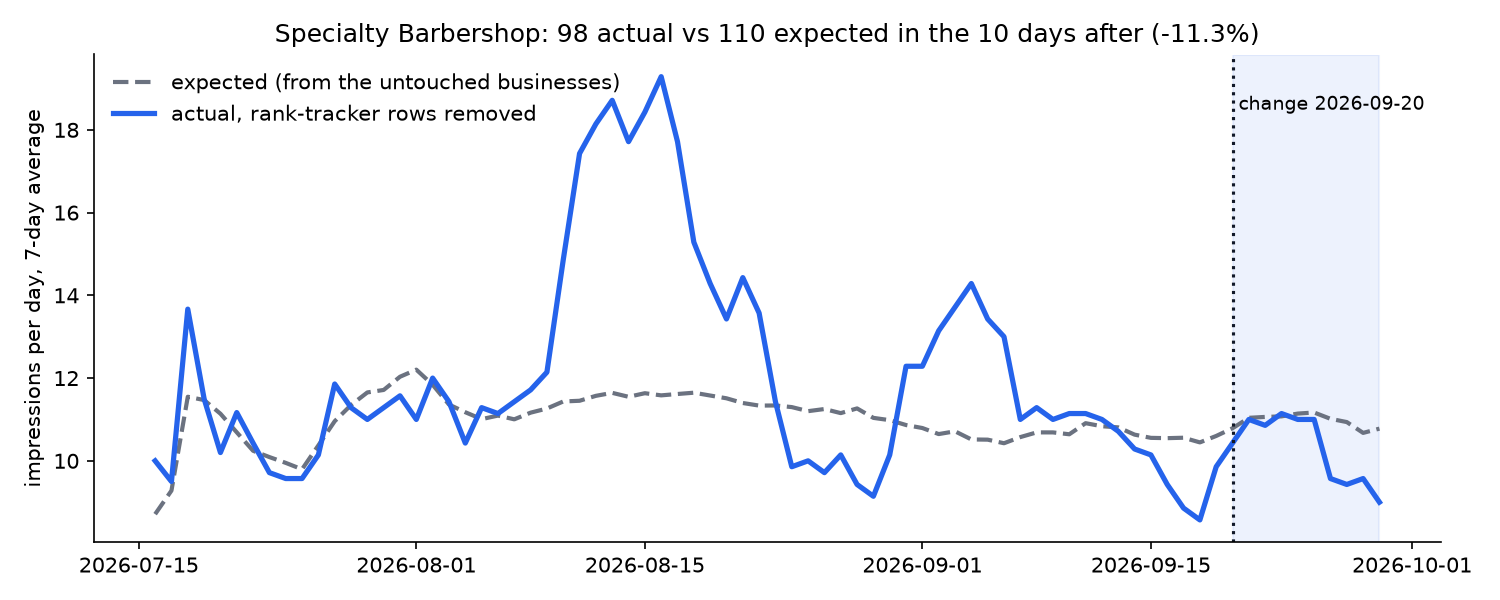

In [4]:
sc.draw(r, TREATED, CHANGE)
display(Image(filename=str(ROOT / "results" / "run" / "synthetic_control.png"), width=900))

### 2b. The same model through the last day we have

The ten-day window above is the clean one. This runs the same model to the last day every business in it has rows for (Search Console's most recent two or three days are still filling in),
once with all four donors and once without the one that changed its own site on September 30,
with placebos, and shows the weeks one by one. The barbershop's new scan phrases were launched on
October 11, so the last week is the one to be careful with.

last day in the data: 2026-10-18 | last day every business in the model has rows: 2026-10-17 (Search Console keeps filling in the most recent two or three days)

4 donors: 2026-09-20 to 2026-10-17, 28 days: 334 actual vs 319.9 expected, +4.4%, placebos 4 of 6 as big
            actual  expected  diff %
date                                
2026-09-26    67.0      77.0   -13.0
2026-10-03    75.0      77.0    -3.0
2026-10-10    73.0      77.0    -5.0
2026-10-17   119.0      89.0    34.0

3 donors, the Sep 30 one removed: 2026-09-20 to 2026-10-17, 28 days: 334 actual vs 321.8 expected, +3.8%, placebos 4 of 5 as big
            actual  expected  diff %
date                                
2026-09-26    67.0      78.0   -14.0
2026-10-03    75.0      77.0    -3.0
2026-10-10    73.0      78.0    -6.0
2026-10-17   119.0      89.0    34.0


chart: /home/mellio/workspace/projects/local-search-reach/results/run/synthetic_control.png

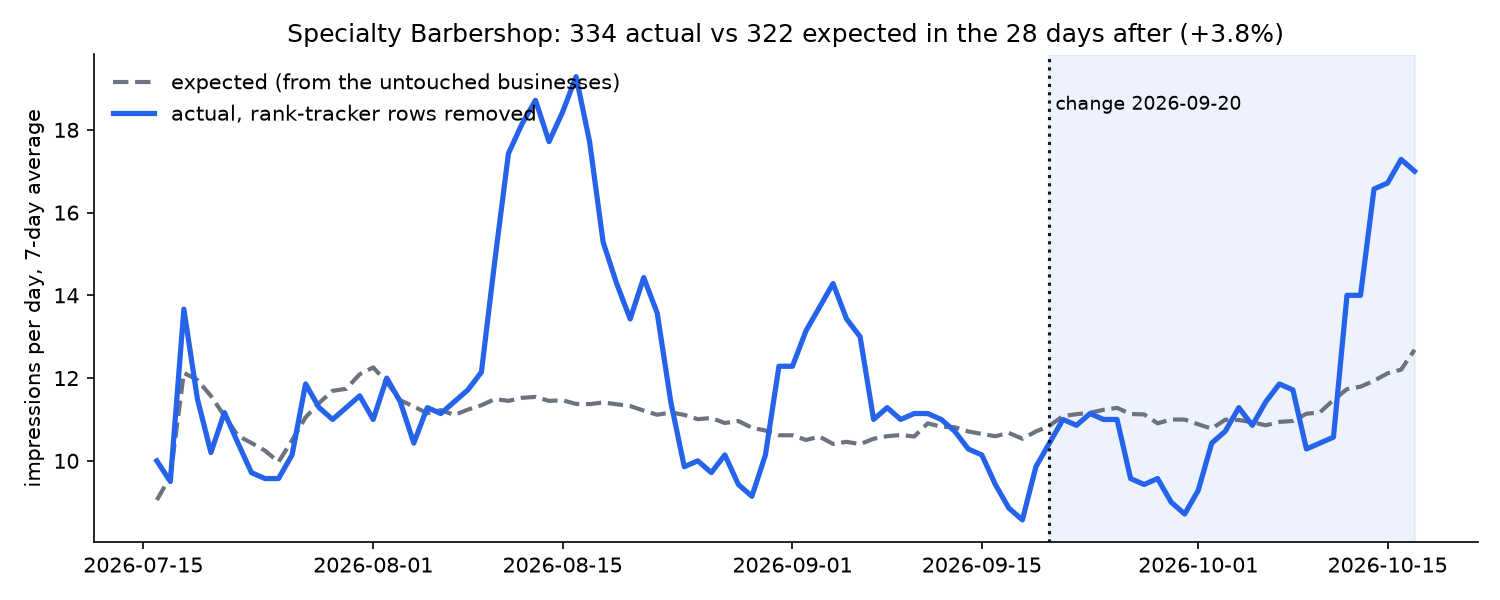

period,before,first 10 days,after that
kind,,,
"kept: desktop, 0 clicks",1.6,1.8,3.2
kept: everything else,8.8,8.0,9.9
removed as rank tracker,0.0,0.0,75.9


In [5]:
last_per_client = g.groupby("client").date.max()
END = last_per_client[[TREATED] + DONORS].min()
print("last day in the data:", daily.index.max().date(), "| last day every business in the model has rows:", END.date(),
      "(Search Console keeps filling in the most recent two or three days)")
runs = {}
for label, donors in [("4 donors", DONORS), ("3 donors, the Sep 30 one removed", DONORS[:3])]:
    rr = sc.fit_predict(daily, TREATED, donors, PRE_START, CHANGE, END)
    pp = sc.placebos(daily, TREATED, donors, PRE_START, CHANGE, rr["post_days"])
    bb = sum(abs(p["effect_pct"]) >= abs(rr["effect_pct"]) for p in pp)
    print(f"\n{label}: {CHANGE.date()} to {END.date()}, {rr['post_days']} days: {rr['post_actual']} actual vs {rr['post_model']} expected, "
          f"{rr['effect_pct']:+.1f}%, placebos {bb} of {len(pp)} as big")
    _, _, _, idx, act, hat = rr["series"]
    wk = pd.DataFrame({"actual": act, "expected": hat}, index=idx).resample("W-SAT").sum().round(0)
    wk["diff %"] = (100 * (wk.actual - wk.expected) / wk.expected).round(0)
    print(wk.to_string())
    runs[label] = rr
sc.draw(runs["3 donors, the Sep 30 one removed"], TREATED, CHANGE)
display(Image(filename=str(ROOT / "results" / "run" / "synthetic_control.png"), width=900))

# what the bot filter kept and removed for the treated business, per day, by period
b = g[(g.client == TREATED) & (g.date >= "2026-09-01")].copy()
b["period"] = np.where(b.date < CHANGE, "before", np.where(b.date <= POST_END, "first 10 days", "after that"))
b["kind"] = np.where(b.is_scan, "removed as rank tracker",
             np.where((b.device == "DESKTOP") & (b.clicks == 0), "kept: desktop, 0 clicks", "kept: everything else"))
days = b.groupby("period").date.nunique()
t = b.pivot_table(index="kind", columns="period", values="impressions", aggfunc="sum").fillna(0)
(t / days).round(1)[["before", "first 10 days", "after that"]]

## 3. How far the reach goes (slide 7)

For each scan: the distance where the chance of being top 3 falls to half of what it is at the
center (r50). Two estimators, kriging (the slides use this one) and logistic. Scans that are top 3
everywhere or nowhere cannot be fitted and are reported as such. The phrase column is left out of
the tables on purpose; some phrases name the home city.

In [6]:
def reach_table(until=None):
    df = reach.load(GEO, until)
    df = df[df["business_name"].isin(THREE)]
    rows = []
    for hid, s in df.groupby("heatmap_id"):
        c = reach.classify(s)
        rows.append(dict(business=s["business_name"].iloc[0], date=s["scan_date"].iloc[0].date(), **c))
    return pd.DataFrame(rows).sort_values(["business", "date"]).reset_index(drop=True)

def summarize(t, label):
    print(label)
    out = []
    for b, gg in t.groupby("business"):
        k, l, ceil = gg["r50_mi"].dropna(), gg["r50_logistic_mi"].dropna(), gg[gg.state == "ceiling"]
        line = f"  {b}: {len(gg)} scans"
        if len(k): line += f", kriging median {k.median():.1f} mi ({len(k)} scans)"
        if len(l): line += f", logistic median {l.median():.1f} mi ({len(l)} scans)"
        if len(ceil): line += f", top 3 everywhere on {len(ceil)} scan(s), farthest point {ceil['at_least_mi'].max():.1f} mi"
        print(line)
        out.append(dict(business=b, kriging=k.median() if len(k) else None, logistic=l.median() if len(l) else None,
                        ceiling=ceil["at_least_mi"].max() if len(ceil) else None))
    return out

t_sep20 = reach_table("2026-09-20")
s_sep20 = summarize(t_sep20, "scans to September 20 (the scans the slides were made from)")
t_all = reach_table()
s_all = summarize(t_all, "\nall scans to October 14")

scans to September 20 (the scans the slides were made from)
  Integrative Health Clinic: 36 scans, kriging median 2.9 mi (14 scans), logistic median 4.3 mi (20 scans), top 3 everywhere on 2 scan(s), farthest point 2.5 mi
  Latin Dance Studio: 8 scans, kriging median 4.1 mi (2 scans), logistic median 4.9 mi (3 scans), top 3 everywhere on 1 scan(s), farthest point 2.1 mi
  Specialty Barbershop: 9 scans, kriging median 1.1 mi (2 scans), logistic median 1.8 mi (2 scans)



all scans to October 14
  Integrative Health Clinic: 52 scans, kriging median 5.1 mi (20 scans), logistic median 4.7 mi (33 scans), top 3 everywhere on 2 scan(s), farthest point 2.5 mi
  Latin Dance Studio: 12 scans, kriging median 4.3 mi (3 scans), logistic median 6.1 mi (4 scans), top 3 everywhere on 1 scan(s), farthest point 2.1 mi
  Specialty Barbershop: 13 scans, kriging median 1.2 mi (3 scans), logistic median 1.5 mi (3 scans), top 3 everywhere on 1 scan(s), farthest point 4.2 mi



chart: /home/mellio/workspace/projects/local-search-reach/results/run/reach.png


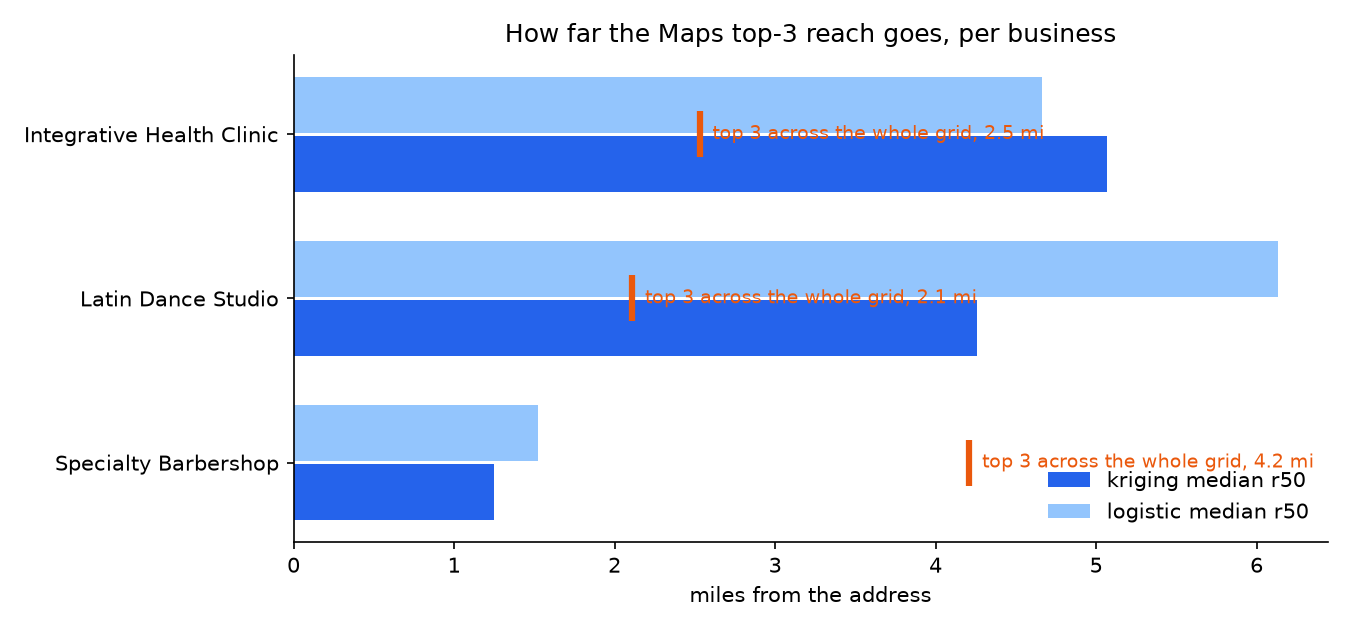

,business,date,points,top3,grid_mi,r50_mi,r50_logistic_mi,state
0,Integrative Health Clinic,2026-08-12,137,1,35.18,NaN,NaN,sparse
1,Integrative Health Clinic,2026-08-12,137,0,35.18,NaN,NaN,floor
2,Integrative Health Clinic,2026-08-18,137,7,35.18,8.44,15.11,fitted
3,Integrative Health Clinic,2026-08-18,137,1,35.18,NaN,NaN,sparse
4,Integrative Health Clinic,2026-08-25,137,2,35.18,NaN,NaN,sparse
...,...,...,...,...,...,...,...,...
72,Specialty Barbershop,2026-09-07,169,148,2.53,NaN,NaN,nofit
73,Specialty Barbershop,2026-10-11,169,1,4.21,NaN,NaN,sparse
74,Specialty Barbershop,2026-10-11,169,169,4.21,NaN,NaN,ceiling
75,Specialty Barbershop,2026-10-11,169,1,4.21,NaN,NaN,sparse


In [7]:
reach.draw(s_all)
display(Image(filename=str(ROOT / "results" / "run" / "reach.png"), width=800))
t_all.drop(columns=["at_least_mi"], errors="ignore")

## 4. Top 3 at home (slide 4)

The slide shows, for each business, its latest scan for the main service phrase that names the
home city. Those scans are on these dates; here is every scan from each date with its top-3 count.

In [8]:
slide_dates = {THREE[0]: "2026-10-11", THREE[1]: "2026-09-07", THREE[2]: "2026-09-29"}
rows = t_all[[d == pd.Timestamp(slide_dates[b]).date() for b, d in zip(t_all.business, t_all.date)]]
rows = rows.assign(top3_share=(100 * rows.top3 / rows.points).round(0))[["business", "date", "points", "top3", "top3_share", "state"]]
rows.sort_values(["business", "top3_share"], ascending=[True, False])

,business,date,points,top3,top3_share,state
44,Integrative Health Clinic,2026-09-29,169,150,89.0,fitted
38,Integrative Health Clinic,2026-09-29,169,134,79.0,fitted
39,Integrative Health Clinic,2026-09-29,169,134,79.0,fitted
40,Integrative Health Clinic,2026-09-29,169,134,79.0,fitted
43,Integrative Health Clinic,2026-09-29,169,131,78.0,fitted
41,Integrative Health Clinic,2026-09-29,169,105,62.0,fitted
42,Integrative Health Clinic,2026-09-29,169,71,42.0,fitted
48,Integrative Health Clinic,2026-09-29,137,13,9.0,fitted
49,Integrative Health Clinic,2026-09-29,137,4,3.0,fitted
45,Integrative Health Clinic,2026-09-29,169,0,0.0,floor


## 5. Confusion matrix and the usual stats

The same per-scan logistic fit, scored out of sample with 5 folds inside each scan, predictions
pooled. Scans that are top 3 everywhere or nowhere are skipped (nothing to classify).

In [9]:
df = reach.load(GEO)
df = df[df["business_name"].isin(THREE)]
for b, gg in df.groupby("business_name"):
    s = clf.score(gg)
    if s is None:
        print(f"\n{b}: not enough variation to score")
    else:
        clf.show(b, s)
s = clf.score(df)
clf.show("All three pooled", s)


Integrative Health Clinic  (5056 grid points, 32 scans, 5 folds)
                   predicted no   predicted top 3
  actually no            1970             567
  actually top 3          337            2182
  accuracy 0.82   precision 0.79   recall 0.87   F1 0.83   AUC 0.89

Latin Dance Studio  (781 grid points, 5 scans, 5 folds)
                   predicted no   predicted top 3
  actually no             174             162
  actually top 3          111             334
  accuracy 0.65   precision 0.67   recall 0.75   F1 0.71   AUC 0.72

Specialty Barbershop  (676 grid points, 4 scans, 5 folds)
                   predicted no   predicted top 3
  actually no             327              66
  actually top 3           30             253
  accuracy 0.86   precision 0.79   recall 0.89   F1 0.84   AUC 0.92



All three pooled  (6513 grid points, 41 scans, 5 folds)
                   predicted no   predicted top 3
  actually no            2471             795
  actually top 3          478            2769
  accuracy 0.80   precision 0.78   recall 0.85   F1 0.81   AUC 0.88


## 6. Summary against the slides

In [10]:
def pick(summary, b, key):
    v = next((x[key] for x in summary if x["business"] == b), None)
    return "" if v is None else f"{v:.1f}"

summary = pd.DataFrame([
    ["slide 6: impressions after the change", "98 actual vs 110 expected, -11%, 4 of 8 placebos as big", f"{r['post_actual']} vs {r['post_model']:.0f}, {r['effect_pct']:+.1f}%, {bigger} of {len(pl)} placebos"],
    ["slide 7: barbershop reach", "4.2 mi (top 3 across the whole October grid)", f"kriging {pick(s_sep20, THREE[0], 'kriging')} mi to Sep 20; all scans {pick(s_all, THREE[0], 'kriging')} mi, ceiling {pick(s_all, THREE[0], 'ceiling')} mi"],
    ["slide 7: dance studio reach", "4.1 mi", f"kriging {pick(s_sep20, THREE[1], 'kriging')} mi to Sep 20; all scans {pick(s_all, THREE[1], 'kriging')} mi"],
    ["slide 7: clinic reach", "2.9 mi", f"kriging {pick(s_sep20, THREE[2], 'kriging')} mi to Sep 20; all scans {pick(s_all, THREE[2], 'kriging')} mi"],
    ["slide 5: clinic rank-tracker share", "70.4% (through Sep 20)", f"{share.loc[THREE[2], 'share'] if THREE[2] in share.index else ''}% (through Oct 15)"],
], columns=["item", "on the slide", "this run"])
summary

,item,on the slide,this run
0,slide 6: impressions after the change,"98 actual vs 110 expected, -11%, 4 of 8 placeb...","98 vs 110, -11.3%, 4 of 8 placebos"
1,slide 7: barbershop reach,4.2 mi (top 3 across the whole October grid),"kriging 1.1 mi to Sep 20; all scans 1.2 mi, ce..."
2,slide 7: dance studio reach,4.1 mi,kriging 4.1 mi to Sep 20; all scans 4.3 mi
3,slide 7: clinic reach,2.9 mi,kriging 2.9 mi to Sep 20; all scans 5.1 mi
4,slide 5: clinic rank-tracker share,70.4% (through Sep 20),73.7% (through Oct 15)
